# 03 · Análisis exploratorio de la brecha digital

## Objetivo
Analizar la distribución territorial y evolución de las conexiones
de internet fijo en el Perú, utilizando los datos depurados de
OSIPTEL y los indicadores trimestrales del INEI.

Los análisis se realizarán sobre las capas Silver y Gold de HDFS,
sin utilizar los registros originales sin depurar.

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
spark = (
    SparkSession.builder
    .appName("OSIPTEL-INEI-Analisis-Exploratorio")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")
base = "hdfs:///datalake/osiptel_proyecto"
osiptel = spark.read.parquet(
    f"{base}/silver/conexiones_osiptel_depuradas"
)
gold = spark.read.parquet(
    f"{base}/gold/conexiones_inei_integradas"
)
print("REGISTROS DISPONIBLES")
print("Silver OSIPTEL:", osiptel.count())
print("Gold integrado:", gold.count())
print("\nCOLUMNAS SILVER")
print(osiptel.columns)
print("\nCOLUMNAS GOLD")
print(gold.columns)

26/10/11 07:26:16 WARN Utils: Your hostname, debian resolves to a loopback address: 127.0.0.1; using 10.0.2.15 instead (on interface enp0s3)
26/10/11 07:26:16 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/11 07:26:17 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


REGISTROS DISPONIBLES
Silver OSIPTEL: 128095
Gold integrado: 27

COLUMNAS SILVER
['mes', 'empresa', 'tecnologia', 'segmento', 'departamento', 'rango_velocidad', 'conexiones', 'anio', 'trimestre', 'fuente_excel', 'version_excel']

COLUMNAS GOLD
['anio', 'trimestre', 'conexiones_fijas', 'filas_osiptel', 'hogares_con_internet_pct', 'fuente_inei_pdf', 'pagina_inei', 'calidad']


TOTAL NACIONAL SILVER - MARZO 2026
4,135,995


,departamento,total_conexiones,fibra_optica,otras_tecnologias
0,LIMA,2130340,1770004,360336
1,LA LIBERTAD,227841,177270,50571
2,AREQUIPA,224313,166708,57605
3,LAMBAYEQUE,178985,154685,24300
4,PIURA,178221,150747,27474
5,CALLAO,167774,137490,30284
6,ICA,146878,133799,13079
7,ANCASH,111981,97947,14034
8,CUSCO,106695,77996,28699
9,JUNIN,99378,87115,12263


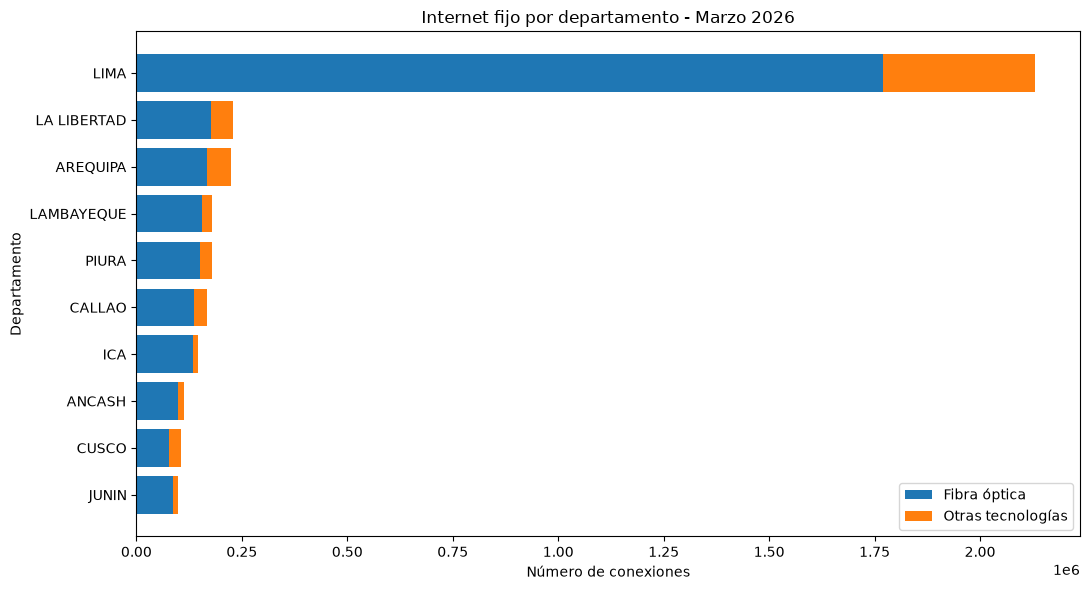

In [2]:
import matplotlib.pyplot as plt
marzo_2026 = osiptel.filter(
    F.date_format("mes", "yyyy-MM") == "2026-03"
)
por_departamento = (
    marzo_2026
    .groupBy("departamento")
    .agg(
        F.sum("conexiones").alias("total_conexiones"),
        F.sum(
            F.when(
                F.lower(F.col("tecnologia")).contains("fibra"),
                F.col("conexiones")
            ).otherwise(0)
        ).alias("fibra_optica")
    )
    .withColumn(
        "otras_tecnologias",
        F.col("total_conexiones") - F.col("fibra_optica")
    )
    .orderBy(F.desc("total_conexiones"))
)
total_nacional = marzo_2026.agg(
    F.sum("conexiones")
).first()[0]
print("TOTAL NACIONAL SILVER - MARZO 2026")
print(f"{total_nacional:,}")
top10 = por_departamento.limit(10).toPandas()
display(top10)
datos_grafico = top10.iloc[::-1]
plt.figure(figsize=(11, 6))
plt.barh(
    datos_grafico["departamento"],
    datos_grafico["fibra_optica"],
    label="Fibra óptica"
)
plt.barh(
    datos_grafico["departamento"],
    datos_grafico["otras_tecnologias"],
    left=datos_grafico["fibra_optica"],
    label="Otras tecnologías"
)
plt.title("Internet fijo por departamento - Marzo 2026")
plt.xlabel("Número de conexiones")
plt.ylabel("Departamento")
plt.legend()
plt.tight_layout()
plt.show()

DEPARTAMENTOS CON MENOR PORCENTAJE DE FIBRA


,departamento,total_conexiones,porcentaje_fibra
0,MADRE DE DIOS,15593,37.19
1,CUSCO,106695,73.10
2,AMAZONAS,13008,73.45
3,AREQUIPA,224313,74.32
4,LORETO,41203,74.95



DEPARTAMENTOS CON MAYOR PORCENTAJE DE FIBRA


,departamento,total_conexiones,porcentaje_fibra
24,TUMBES,38610,92.47
23,ICA,146878,91.10
22,MOQUEGUA,29256,90.40
21,SAN MARTIN,52039,89.12
20,JUNIN,99378,87.66


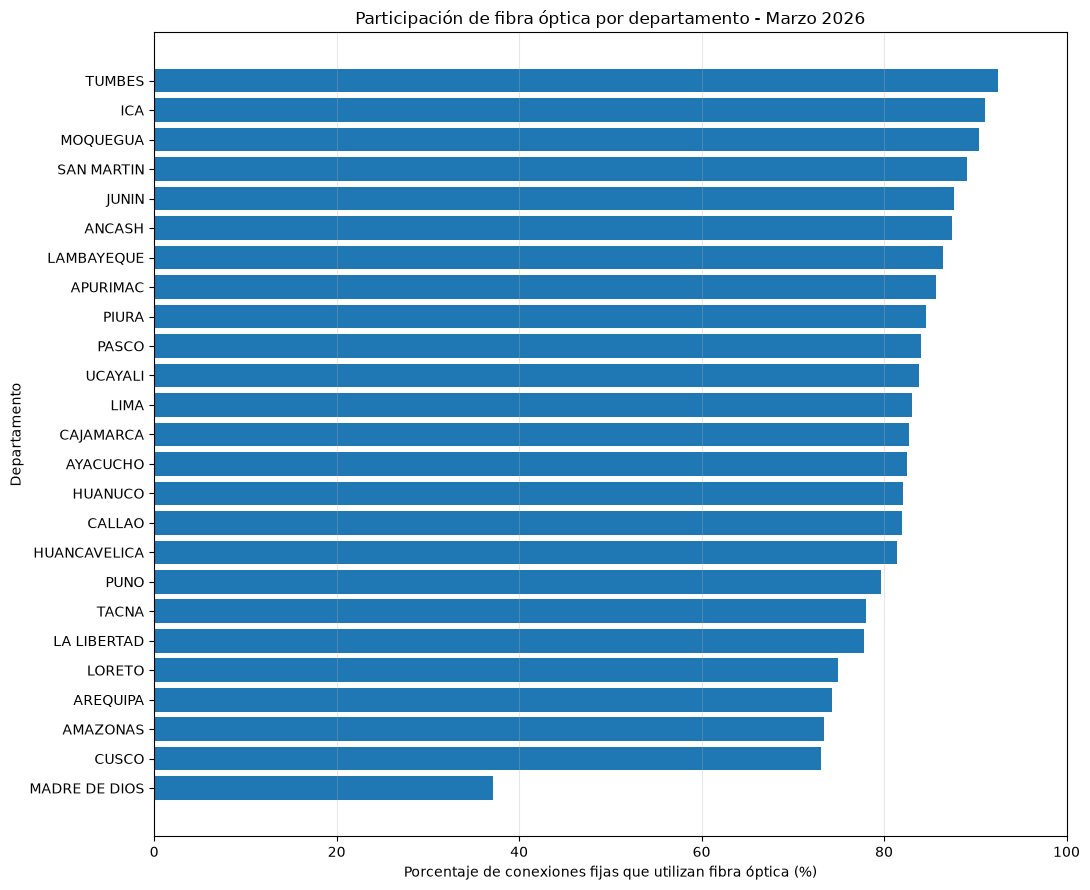

In [3]:
porcentaje_departamento = (
    por_departamento
    .filter(F.col("total_conexiones") > 0)
    .withColumn(
        "porcentaje_fibra",
        F.round(
            F.col("fibra_optica") /
            F.col("total_conexiones") * 100,
            2
        )
    )
    .orderBy("porcentaje_fibra")
)
df_porcentajes = porcentaje_departamento.toPandas()
print("DEPARTAMENTOS CON MENOR PORCENTAJE DE FIBRA")
display(
    df_porcentajes[
        ["departamento", "total_conexiones", "porcentaje_fibra"]
    ].head(5)
)
print("\nDEPARTAMENTOS CON MAYOR PORCENTAJE DE FIBRA")
display(
    df_porcentajes[
        ["departamento", "total_conexiones", "porcentaje_fibra"]
    ].tail(5).sort_values("porcentaje_fibra", ascending=False)
)
plt.figure(figsize=(11, 9))
plt.barh(
    df_porcentajes["departamento"],
    df_porcentajes["porcentaje_fibra"]
)
plt.title("Participación de fibra óptica por departamento - Marzo 2026")
plt.xlabel("Porcentaje de conexiones fijas que utilizan fibra óptica (%)")
plt.ylabel("Departamento")
plt.xlim(0, 100)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

ÚLTIMOS INDICADORES INEI EN GOLD


,anio,trimestre,hogares_con_internet_pct
19,2024,1,58.4
20,2024,2,57.9
21,2024,3,58.2
22,2024,4,58.4
23,2025,2,60.7
24,2025,3,59.8
25,2025,4,60.2
26,2026,1,62.7


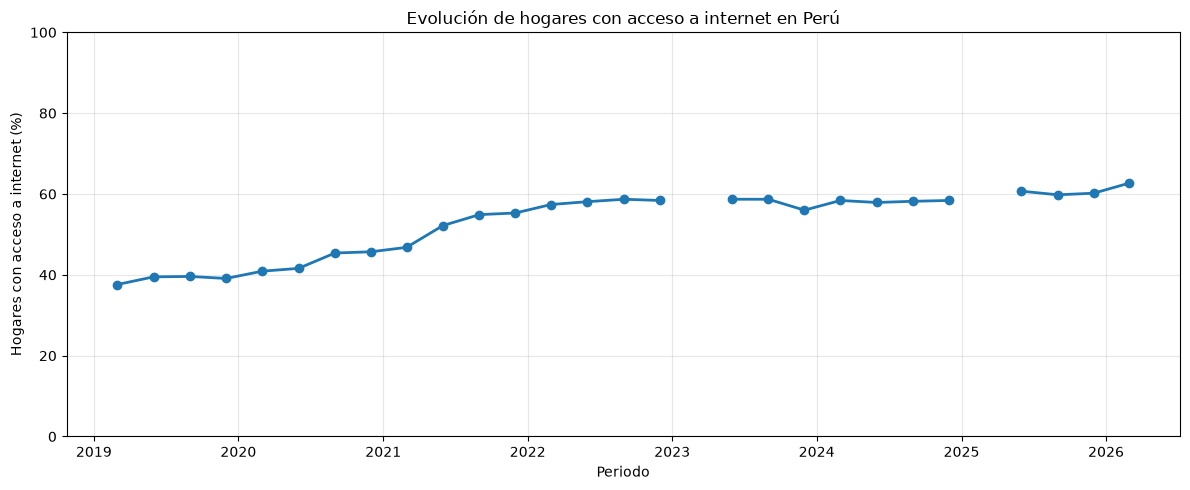

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
serie_inei = (
    gold
    .select(
        "anio",
        "trimestre",
        "hogares_con_internet_pct"
    )
    .orderBy("anio", "trimestre")
    .toPandas()
)
serie_inei["fecha"] = pd.to_datetime(
    serie_inei["anio"].astype(str)
    + "-"
    + (serie_inei["trimestre"] * 3)
        .astype(str).str.zfill(2)
    + "-01"
)
serie_grafico = (
    serie_inei
    .set_index("fecha")["hogares_con_internet_pct"]
    .asfreq("QS-MAR")
)
print("ÚLTIMOS INDICADORES INEI EN GOLD")

display(
    serie_inei[
        ["anio", "trimestre", "hogares_con_internet_pct"]
    ].tail(8)
)
plt.figure(figsize=(12, 5))
plt.plot(
    serie_grafico.index,
    serie_grafico.values,
    marker="o",
    linewidth=2
)
plt.title(
    "Evolución de hogares con acceso a internet en Perú"
)
plt.xlabel("Periodo")
plt.ylabel("Hogares con acceso a internet (%)")
plt.ylim(0, 100)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

COMPARACIÓN OSIPTEL - INEI
Periodo base: 2019-03
OSIPTEL base: 2,235,850 conexiones
INEI base: 37.60%


,anio,trimestre,indice_osiptel,indice_inei
fecha,,,,
2024-03-01,2024,1,164.11,155.32
2024-06-01,2024,2,169.99,153.99
2024-09-01,2024,3,176.78,154.79
2024-12-01,2024,4,179.55,155.32
2025-06-01,2025,2,187.60,161.44
2025-09-01,2025,3,191.86,159.04
2025-12-01,2025,4,195.88,160.11
2026-03-01,2026,1,184.99,166.76


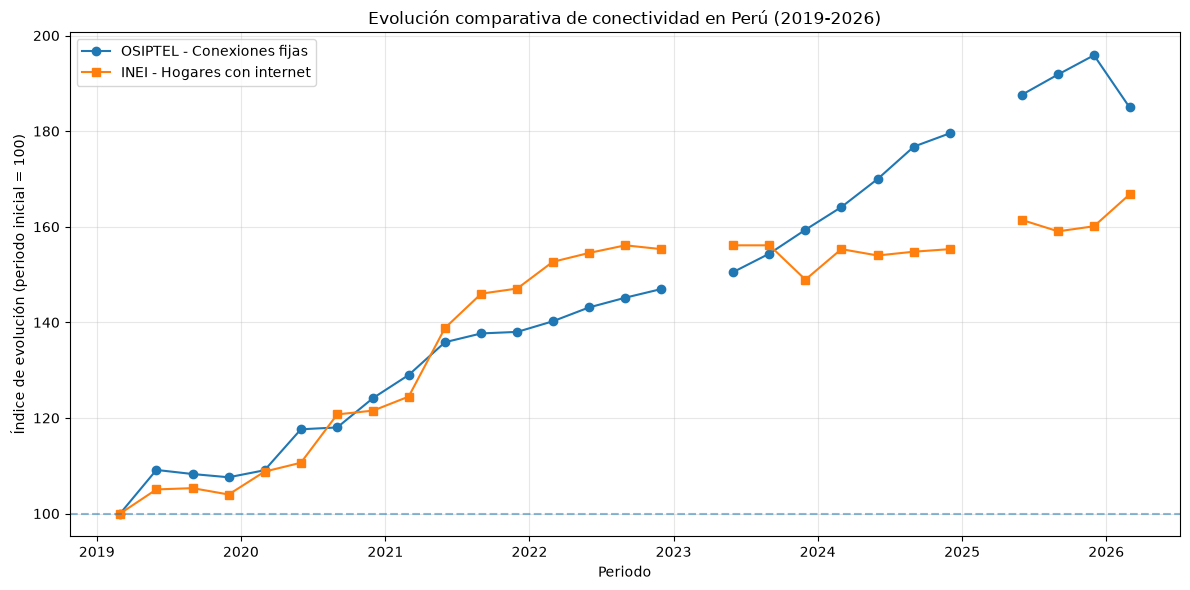

In [6]:
comparacion = (
    gold
    .select(
        "anio",
        "trimestre",
        "conexiones_fijas",
        "hogares_con_internet_pct"
    )
    .orderBy("anio", "trimestre")
    .toPandas()
)
comparacion["fecha"] = pd.to_datetime({
    "year": comparacion["anio"],
    "month": comparacion["trimestre"] * 3,
    "day": 1
})
comparacion = comparacion.set_index("fecha").sort_index()
base_osiptel = comparacion["conexiones_fijas"].iloc[0]
base_inei = comparacion["hogares_con_internet_pct"].iloc[0]
comparacion["indice_osiptel"] = (
    comparacion["conexiones_fijas"] / base_osiptel * 100
)
comparacion["indice_inei"] = (
    comparacion["hogares_con_internet_pct"] / base_inei * 100
)
serie_completa = comparacion[
    ["indice_osiptel", "indice_inei"]
].asfreq("QS-MAR")
print("COMPARACIÓN OSIPTEL - INEI")
print("Periodo base:", comparacion.index[0].strftime("%Y-%m"))
print("OSIPTEL base:", f"{base_osiptel:,.0f}", "conexiones")
print("INEI base:", f"{base_inei:.2f}%")
display(
    comparacion[
        ["anio", "trimestre", "indice_osiptel", "indice_inei"]
    ].tail(8).round(2)
)
plt.figure(figsize=(12, 6))
plt.plot(
    serie_completa.index,
    serie_completa["indice_osiptel"],
    marker="o",
    label="OSIPTEL - Conexiones fijas"
)
plt.plot(
    serie_completa.index,
    serie_completa["indice_inei"],
    marker="s",
    label="INEI - Hogares con internet"
)
plt.axhline(100, linestyle="--", alpha=0.5)
plt.title("Evolución comparativa de conectividad en Perú (2019-2026)")
plt.xlabel("Periodo")
plt.ylabel("Índice de evolución (periodo inicial = 100)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Conclusiones del análisis exploratorio

El análisis exploratorio se realizó utilizando los datos depurados almacenados en Silver y los indicadores integrados en Gold de HDFS.

**Gráfico 1 — Distribución territorial:** Se identificó una elevada concentración de conexiones de internet fijo en Lima, seguida de departamentos como La Libertad, Arequipa, Lambayeque y Piura.

**Gráfico 2 — Participación de fibra óptica:** Se encontraron diferencias territoriales importantes. Madre de Dios presentó una participación de fibra óptica del 37.19 %, mientras que Tumbes alcanzó el 92.47 % en marzo de 2026.

**Gráfico 3 — Acceso de hogares a internet:** Los indicadores del INEI muestran una tendencia general de crecimiento durante el periodo analizado. Algunos trimestres están ausentes de Gold debido a controles de calidad aplicados a OSIPTEL.

**Gráfico 4 — Comparación OSIPTEL e INEI:** La normalización mediante índices de base 100 permitió comparar la evolución relativa de las conexiones fijas y del porcentaje de hogares con acceso a internet.

### Limitaciones

Los indicadores utilizados representan fenómenos distintos. OSIPTEL registra conexiones de internet fijo, mientras que el INEI mide el acceso a internet en los hogares, incluyendo otras formas de conectividad.

Asimismo, la comparación integrada actualmente tiene granularidad nacional y trimestral. Por tanto, las diferencias departamentales observadas describen la distribución y composición tecnológica de las conexiones fijas, pero no constituyen por sí solas una medición completa de la brecha digital territorial.

### Conclusión general

Se identificaron desigualdades territoriales en la distribución y composición tecnológica del internet fijo, junto con una evolución general positiva del acceso a internet en los hogares peruanos.

Estos resultados constituyen una base descriptiva para continuar investigando las brechas de conectividad y evaluar posibles indicadores o modelos analíticos.